[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_vr_periods/BA_L2_vr_periods.ipynb)

# BA_L2_vr_periods: Variance Ratios by Sub-Period

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Robust variance-ratio statistic Z*(5) of Lo and MacKinlay for Bitcoin, Ethereum and the S&P 500 in three sub-periods, 2014-2017 (Ethereum from 2016), 2018-2021 and 2022 to 18 September 2026.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

`close_cal(sym, start)` keeps each asset on its own calendar: crypto trades every day; for the S&P 500 and gold only
Monday–Friday closes are kept and repeated closes (holidays filled with the last price) are removed.
`log_returns(sym)` gives the daily log returns in percent, $r_t = 100(\ln P_t - \ln P_{t-1})$, of 2018–2026.

The variance ratio $\mathrm{VR}(q)$ compares the variance of $q$-day returns with $q$ times the daily variance; it is 1
under a random walk. The robust statistic $Z^*(q)$ of Lo and MacKinlay (1988) allows for volatility clustering; the
random walk is rejected at 5% if $|Z^*(q)| > 1.96$. Here $q = 5$.

**How to read the chart.** One bar per asset and sub-period; a bar beyond the dashed lines would reject the random
walk in that sub-period.

In [5]:
from scipy import stats
import statsmodels.api as sm


def close_cal(sym, start, end=END):
    # closes on the asset's own calendar: crypto every day; S&P 500 and gold Monday-Friday, repeated closes removed
    s = daily(sym, end).loc[start:]
    if not sym.endswith('.CC'):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def log_returns(sym, start='2017-12-31', first='2018-01-01', end=END):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1}), from `first`
    return (100 * np.log(close_cal(sym, start, end)).diff()).dropna().loc[first:]

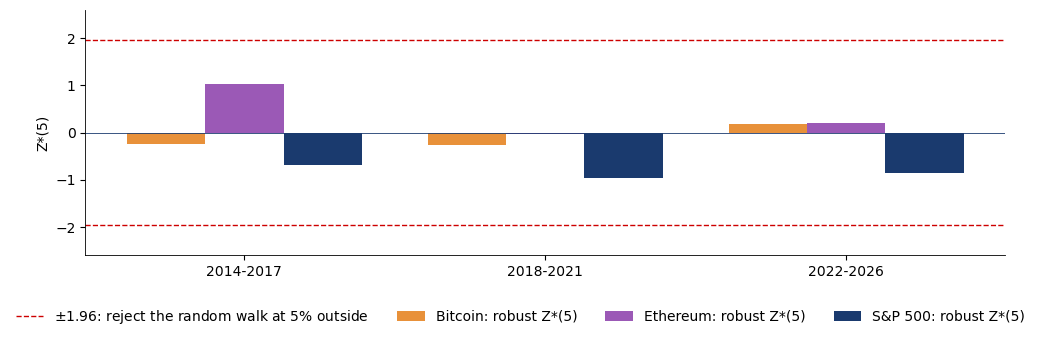

   asset    period      start    n  VR(5)  Z*(5)
 Bitcoin 2014-2017 2014-09-17 1201  0.975 -0.234
 Bitcoin 2018-2021 2018-01-01 1460  0.981 -0.252
 Bitcoin 2022-2026 2022-01-01 1721  1.013  0.181
Ethereum 2014-2017 2016-01-01  730  1.127  1.031
Ethereum 2018-2021 2018-01-01 1460  0.997 -0.037
Ethereum 2022-2026 2022-01-01 1721  1.014  0.197
 S&P 500 2014-2017 2014-09-17  827  0.916 -0.680
 S&P 500 2018-2021 2018-01-01 1007  0.784 -0.954
 S&P 500 2022-2026 2022-01-01 1181  0.918 -0.849


In [6]:
# robust variance-ratio statistic Z*(5) by sub-period
def vr_robust(x, q):
    x = np.asarray(x, float); T = len(x); mu = x.mean(); e = x - mu
    var_a = np.sum(e ** 2) / (T - 1)
    agg = np.convolve(x, np.ones(q), mode='valid') - q * mu
    m = q * (T - q + 1) * (1 - q / T)
    vr = (np.sum(agg ** 2) / m) / var_a
    den = np.sum(e ** 2) ** 2
    theta = sum((2 * (q - j) / q) ** 2 * T * np.sum(e[j:] ** 2 * e[:-j] ** 2) / den for j in range(1, q))
    return vr, (vr - 1) / np.sqrt(theta / T)


PERIODS = [('2014-09-17', '2017-12-31'), ('2018-01-01', '2021-12-31'), ('2022-01-01', END)]
FIRST = {'Bitcoin': '2014-09-17', 'Ethereum': '2016-01-01', 'S&P 500': '2014-09-17'}
vrp = []
for nm, sym in [('Bitcoin', 'BTC-USD.CC'), ('Ethereum', 'ETH-USD.CC'), ('S&P 500', 'GSPC.INDX')]:
    for a0, e_ in PERIODS:
        a = max(a0, FIRST[nm])                            # Ethereum starts in 2016
        x_ = (100 * np.log(close_cal(sym, a, e_))).diff().dropna().values
        vr_, zs_ = vr_robust(x_, 5)
        vrp.append({'asset': nm, 'period': f'{a0[:4]}-{e_[:4]}', 'start': a, 'n': len(x_), 'VR(5)': vr_, 'Z*(5)': zs_})
vrp = pd.DataFrame(vrp)

fig, ax = plt.subplots(figsize=(10, 3.4))
labs = vrp['period'].unique(); x_ = np.arange(len(labs)); w_ = 0.26
for i, (nm, col) in enumerate([('Bitcoin', BTC), ('Ethereum', ETH), ('S&P 500', BLUE)]):
    v_ = vrp[vrp['asset'] == nm].set_index('period')['Z*(5)'].reindex(labs)
    ax.bar(x_ + (i - 1) * w_, v_.values, w_, color=col, label=f'{nm}: robust Z*(5)')
ax.axhline(1.96, color=RED, ls='--', lw=1, label=r'$\pm 1.96$: reject the random walk at 5% outside'); ax.axhline(-1.96, color=RED, ls='--', lw=1)
ax.axhline(0, color=BLUE, lw=0.6)
ax.set_xticks(x_); ax.set_xticklabels(labs); ax.set_ylabel('Z*(5)'); ax.set_ylim(-2.6, 2.6)
legend_below(fig, ncol=4, bottom=0.12)
save_fig(fig, 'ba_l2_vr_periods')
print(vrp.round(3).to_string(index=False))